# Discretionary Space

Publication-oriented descriptive visualizations of the developer survey. Each notebook reads the Excel workbook from **the same folder as the notebook** and saves vector PDFs and high-resolution PNGs under `figures/discretionary_space/`.

- The source workbook is not modified.
- Frequencies are calculated from the data at execution time (not hard-coded).
- For single-choice questions, percentages use valid responses to that question; missing answers are reported separately.
- For multi-select questions, percentages are percentages of respondents, so they need **not** sum to 100%.
- Category labels are taken directly from the survey; manual recoding is avoided.


In [1]:
FOLDER = 'discretionary_space'
from pathlib import Path
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, PercentFormatter

# Put the original .xlsx alongside this notebook.
EXCEL_FILE = None  # Optionally specify a filename, e.g. "survey.xlsx"
ROOT = Path.cwd()
files = sorted(p for p in ROOT.glob("*.xlsx") if not p.name.startswith("~$"))
if EXCEL_FILE is None:
    if len(files) != 1:
        raise FileNotFoundError(f"Expected exactly one .xlsx alongside the notebook, found {len(files)}: {[p.name for p in files]}. Set EXCEL_FILE above.")
    excel_path = files[0]
else:
    excel_path = ROOT / EXCEL_FILE
raw = pd.read_excel(excel_path)
N = len(raw)
FIG_DIR = ROOT / "figures" / FOLDER
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Restrained, colorblind-conscious palette. All charts use the same styling.
INK = '#202a34'
BLUE = '#396ba4'
TEAL = '#368a82'
PALE = '#e7ebef'
PALETTE = ['#4878a8', '#6c91b6', '#8bb7ad', '#d9b26f', '#ba7383', '#857cae', '#8e9eab']
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9.5, 'axes.labelsize': 9.5,
    'axes.titlesize': 11, 'axes.titleweight': 'semibold',
    'axes.edgecolor': '#bfc6ce', 'axes.labelcolor': INK,
    'text.color': INK, 'xtick.color': INK, 'ytick.color': INK,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white', 'pdf.fonttype': 42, 'ps.fonttype': 42,
})

def col(index):
    """Index is from the original workbook (0-based), to avoid ambiguity in long survey questions."""
    return raw.iloc[:, index]

def wrap(value, width=43):
    return '\n'.join(textwrap.wrap(str(value), width=width, break_long_words=False, break_on_hyphens=False))

def save_plot(fig, slug):
    for ext in ('pdf', 'png'):
        fig.savefig(FIG_DIR / f'{slug}.{ext}', bbox_inches='tight',
                    dpi=350 if ext == 'png' else None, pad_inches=0.16)
    plt.show()
    plt.close(fig)

def single(index, title, slug, order=None, labels=None):
    series = col(index).dropna().astype(str).str.strip()
    counts = series.value_counts()
    if order is not None:
        counts = counts.reindex([key for key in order if key in counts.index], fill_value=0)
        other = series.value_counts().drop(index=counts.index, errors='ignore')
        counts = pd.concat([counts, other])
    if labels is not None:
        counts.index = [labels.get(k, k) for k in counts.index]
    denom = len(series)
    values = 100 * counts / denom
    labels_wrapped = [wrap(k) for k in counts.index]
    fig, ax = plt.subplots(figsize=(8.4, max(2.7, len(counts)*0.52 + 0.7)))
    pos = np.arange(len(counts))
    ax.barh(pos, values, color=BLUE, height=.69)
    ax.set_yticks(pos, labels_wrapped)
    ax.invert_yaxis()
    ax.set_xlim(0, max(30, np.ceil(values.max()/10)*10 + 12))
    ax.set_xlabel('Respondents (%)')
    ax.set_title(title, loc='left', pad=14)
    ax.xaxis.set_major_locator(MultipleLocator(20))
    ax.grid(axis='x', color=PALE, lw=.7)
    ax.set_axisbelow(True)
    ax.tick_params(axis='y', length=0, pad=8)
    for i, (pct, count) in enumerate(zip(values, counts)):
        ax.text(pct + 0.8, i, f'{pct:.1f}%  (n={count})', va='center', fontsize=8.1)
    fig.text(.99, .005, f'Valid n={denom}; missing n={N-denom}', ha='right', fontsize=8, color='#5d6872')
    fig.tight_layout(rect=(0, .025, 1, 1))
    save_plot(fig, slug)
    return counts

def multiple(index, title, slug, top=None):
    valid = col(index).dropna().astype(str)
    # Survey exports use comma-space delimiters for checkbox items.
    choices = valid.apply(lambda s: list(dict.fromkeys(x.strip() for x in s.split(', ') if x.strip())))
    counts = pd.Series([choice for row in choices for choice in row]).value_counts()
    if top is not None:
        counts = counts.head(top)
    counts = counts.sort_values()
    vals = counts * 100 / len(valid)
    fig, ax = plt.subplots(figsize=(9.0, max(3.1, len(counts)*.37 + .85)))
    y = np.arange(len(counts))
    ax.barh(y, vals, color=TEAL, height=.73)
    ax.set_yticks(y, [wrap(s, 46) for s in counts.index])
    ax.tick_params(axis='y', length=0, pad=8)
    ax.set_xlim(0, max(30, np.ceil(vals.max()/10)*10 + 10))
    ax.set_xlabel('Respondents selecting the option (%)')
    ax.set_title(title, loc='left', pad=14)
    ax.xaxis.set_major_locator(MultipleLocator(20))
    ax.grid(axis='x', color=PALE, lw=.7)
    ax.set_axisbelow(True)
    for i, (v, count) in enumerate(zip(vals, counts)):
        ax.text(v + .75, i, f'{v:.1f}% (n={count})', va='center', fontsize=8)
    fig.text(.99, .005, f'Multiple selections permitted; valid n={len(valid)}; missing n={N-len(valid)}',
             ha='right', fontsize=8, color='#5d6872')
    fig.tight_layout(rect=(0, .026, 1, 1))
    save_plot(fig, slug)
    return counts

print(f'Workbook: {excel_path.name} | Respondents: {N} | Output: {FIG_DIR}')


Workbook: developers-answers.xlsx | Respondents: 104 | Output: /Users/sara/Documents/Repo/developers-agency-llm/rq1/figures/discretionary_space


## Requirements and constraints (multiple selections)

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


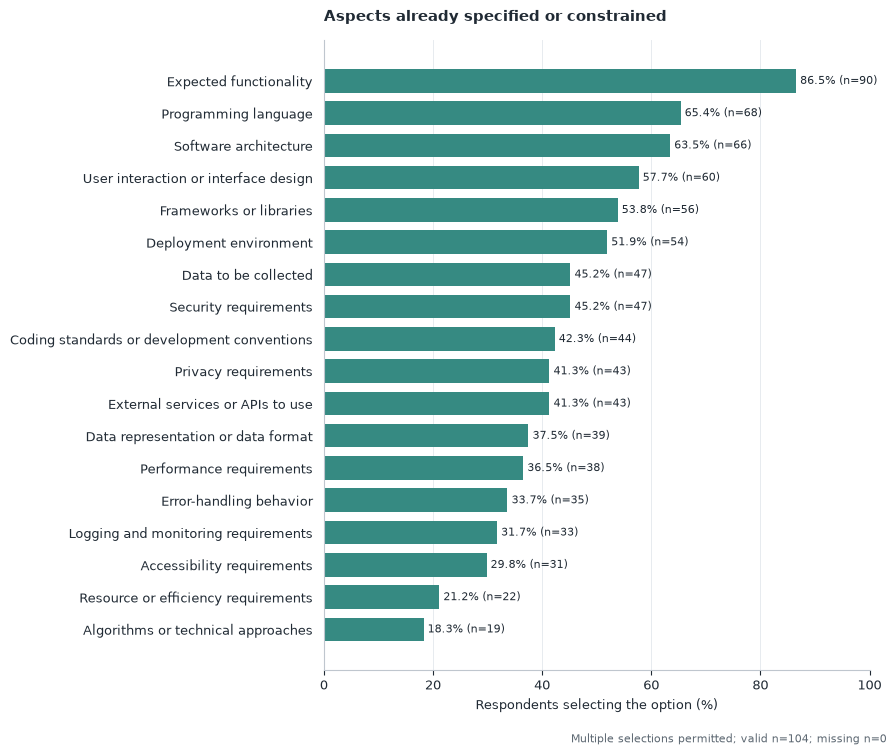

Algorithms or technical approaches             19
Resource or efficiency requirements            22
Accessibility requirements                     31
Logging and monitoring requirements            33
Error-handling behavior                        35
Performance requirements                       38
Data representation or data format             39
External services or APIs to use               43
Privacy requirements                           43
Coding standards or development conventions    44
Security requirements                          47
Data to be collected                           47
Deployment environment                         54
Frameworks or libraries                        56
User interaction or interface design           60
Software architecture                          66
Programming language                           68
Expected functionality                         90
Name: count, dtype: int64

In [2]:
multiple(10, 'Aspects already specified or constrained', 'requirements_constraints')

## Degree of implementation discretion

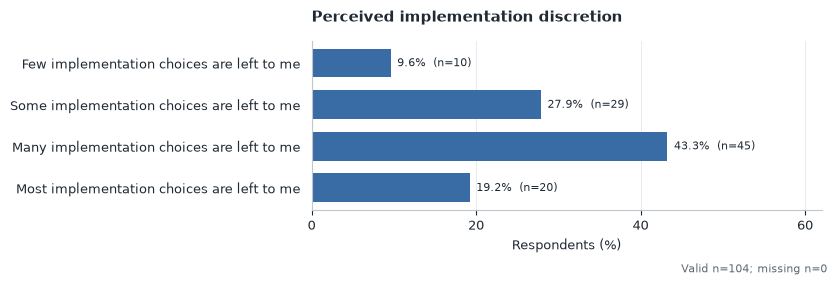

Thinking about your current project, how much implementation discretion do you typically have once all requirements and constraints have been defined?
Few implementation choices are left to me     10
Some implementation choices are left to me    29
Many implementation choices are left to me    45
Most implementation choices are left to me    20
Name: count, dtype: int64

In [3]:
single(17, 'Perceived implementation discretion', 'discretion_degree', order=['Few implementation choices are left to me','Some implementation choices are left to me','Many implementation choices are left to me','Most implementation choices are left to me'])

## Discretionary choices (multiple selections)

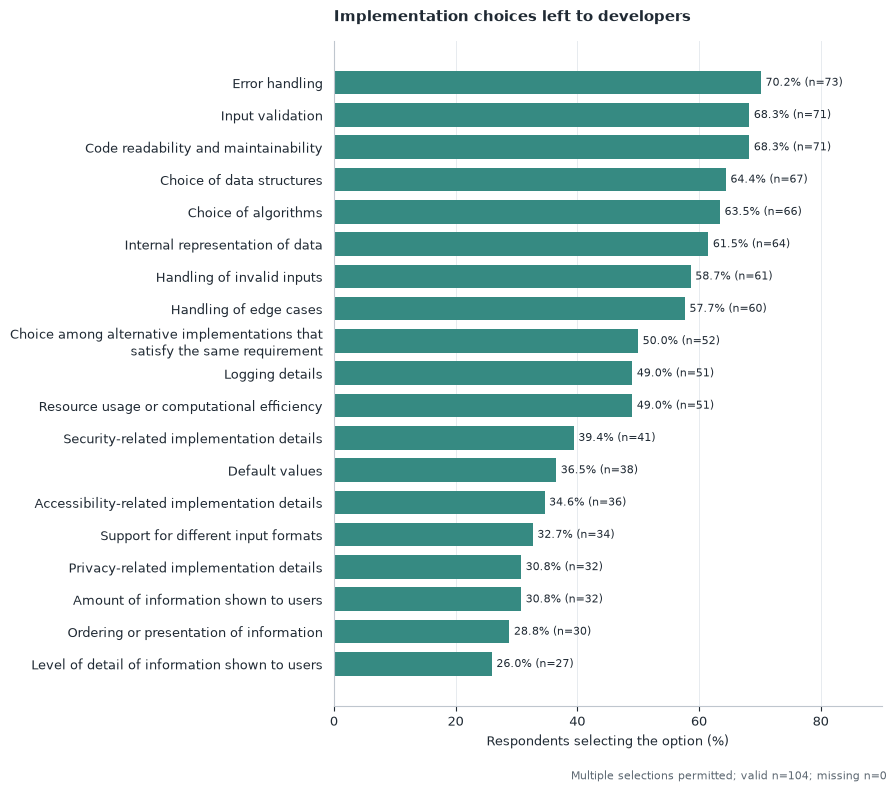

Level of detail of information shown to users                                 27
Ordering or presentation of information                                       30
Amount of information shown to users                                          32
Privacy-related implementation details                                        32
Support for different input formats                                           34
Accessibility-related implementation details                                  36
Default values                                                                38
Security-related implementation details                                       41
Resource usage or computational efficiency                                    51
Logging details                                                               51
Choice among alternative implementations that satisfy the same requirement    52
Handling of edge cases                                                        60
Handling of invalid inputs  

In [4]:
multiple(18, 'Implementation choices left to developers', 'discretionary_choices')

## Personal priorities and values

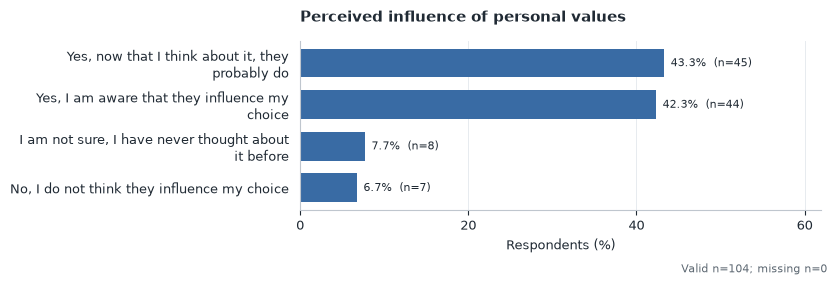

When you choose among multiple implementations that all satisfy the given requirements and constraints, do you think that your personal priorities or values may influence your choice?
Yes, now that I think about it, they probably do       45
Yes, I am aware that they influence my choice          44
I am not sure, I have never thought about it before     8
No, I do not think they influence my choice             7
Name: count, dtype: int64

In [5]:
single(20, 'Perceived influence of personal values', 'personal_values')

## Broader consequences

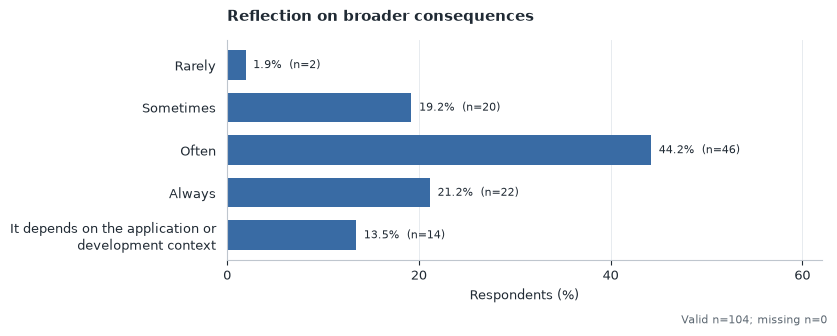

How often do you consciously reflect on the broader consequences of an implementation choice?
Rarely                                                   2
Sometimes                                               20
Often                                                   46
Always                                                  22
It depends on the application or development context    14
Name: count, dtype: int64

In [6]:
single(21, 'Reflection on broader consequences', 'broader_consequences', order=['Rarely','Sometimes','Often','Always','It depends on the application or development context'])

## Six soft-ethical aspects

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


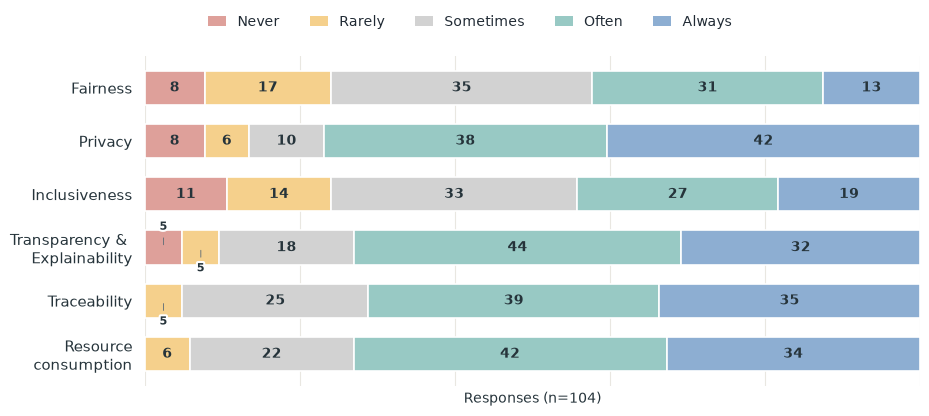

In [7]:
# Build the ordered response table directly from the workbook.
levels = ['Never', 'Rarely', 'Sometimes', 'Often', 'Always']
aspects = [
    'Fairness', 'Privacy', 'Inclusiveness',
    'Transparency / Explainability', 'Traceability', 'Resource consumption'
]
results = pd.DataFrame([
    col(index).dropna().astype(str).str.strip().value_counts().reindex(levels, fill_value=0)
    for index in range(22, 28)
], index=aspects).astype(int)
valid_n = results.sum(axis=1)
percentages = results.div(valid_n.replace(0, np.nan), axis=0).mul(100).fillna(0)

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib import patheffects

# Publication-oriented styling
INK = '#26343B'
MUTED = '#647078'
PALE = '#E9E7E1'
PAPER = '#FFFFFF'


colors = [
    "#DEA09A",  # Never - pastel terracotta
    "#F5D08C",  # Rarely - pastel golden yellow
    "#D2D2D2",  # Sometimes - soft neutral gray
    "#98C9C4",  # Often - pastel teal
    "#8DAED2",  # Always - pastel blue
]

labels = [
    'Fairness',
    'Privacy',
    'Inclusiveness',
    'Transparency & \n Explainability',
    'Traceability',
    'Resource\nconsumption'
]

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'savefig.facecolor': PAPER,
})

fig, ax = plt.subplots(figsize=(12.5, 5.6))
fig.patch.set_facecolor(PAPER)
ax.set_facecolor(PAPER)

y = np.arange(len(aspects))
left = np.zeros(len(aspects), dtype=float)

bar_height = 0.64

for j, (level, color) in enumerate(zip(levels, colors)):
    pct = percentages[level].to_numpy(dtype=float)
    counts = results[level].to_numpy(dtype=int)

    ax.barh(
        y, pct, left=left,
        height=bar_height,
        color=color,
        edgecolor=PAPER,
        linewidth=1.2,
        zorder=3
    )

    for i, (v, count) in enumerate(zip(pct, counts)):
        if count == 0:
            continue

        center = left[i] + v / 2

        # All nonzero counts, including narrow segments.
        # Narrow segments use an external callout to avoid overlap.
        if v >= 5.5:
            text_color = '#26343B'

            ax.text(
                center, y[i], f'{count}',
                ha='center', va='center',
                fontsize=10,
                fontweight='bold',
                color=text_color,
                zorder=5
            )
        else:
            # Alternate vertical offsets for adjacent
            # small segments to improve readability.
            offset = -0.39 if j % 2 == 0 else 0.39

            annotation = ax.annotate(
                str(count),
                xy=(center, y[i]),
                xytext=(center, y[i] + offset),
                ha='center',
                va='center',
                fontsize=8,
                fontweight='semibold',
                color=INK,
                arrowprops=dict(
                    arrowstyle='-',
                    color=MUTED,
                    lw=0.65,
                    shrinkA=2,
                    shrinkB=2
                ),
                zorder=6,
                annotation_clip=False
            )
            annotation.set_path_effects([
                patheffects.withStroke(
                    linewidth=3,
                    foreground=PAPER
                )
            ])

    left += pct

# Axes
ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=11, color=INK)
ax.invert_yaxis()

ax.set_xlim(0, 100)
ax.set_xticks(np.arange(0, 101, 20))
ax.set_xticklabels(
    [f'{x}%' for x in range(0, 101, 20)],
    fontsize=9,
    color=MUTED
)


ax.grid(
    axis='x',
    color=PALE,
    linewidth=0.8,
    zorder=0
)
ax.set_axisbelow(True)
ax.tick_params(axis='both', length=0, pad=9)
ax.tick_params(axis='x', labelbottom=False)

for spine in ax.spines.values():
    spine.set_visible(False)

total_n = 0
# Add valid sample size to the right of each bar
for i, n in enumerate(valid_n):
    total_n = n
    ax.text(
        102, y[i], None,
        ha='left', va='center',
        fontsize=9,
        color=MUTED,
        clip_on=False
    )
    
ax.set_xlabel(f'Responses (n={total_n})', fontsize=10, color=INK)


# Title and subtitle
# fig.text(
#     0.08, 0.955,
#     'Soft-ethical aspects',
#     fontsize=17,
#     fontweight='bold',
#     color=INK,
#     ha='left'
# )

# fig.text(
#     0.08, 0.908,
#     'Distribution of response frequencies across six aspects',
#     fontsize=10,
#     color=MUTED,
#     ha='left'
# )

# Legend
handles = [
    Patch(facecolor=c, edgecolor='none', label=l)
    for l, c in zip(levels, colors)
]

fig.legend(
    handles=handles,
    ncol=5,
    loc='upper center',
    bbox_to_anchor=(0.53, 0.865),
    frameon=False,
    fontsize=10,
    handlelength=1.3,
    columnspacing=2.2
)

# Footnote
# fig.text(
#     0.08, 0.055,
#     'Note: Numbers indicate respondent counts. '
#     'Bar widths represent percentages of valid responses. '
#     'Zero counts are omitted.',
#     fontsize=8.5,
#     color=MUTED,
#     ha='left'
# )

fig.subplots_adjust(
    left=0.27,
    right=0.89,
    top=0.77,
    bottom=0.18
)

# Export as publication-ready vector PDF and PNG
fig.savefig(
    'ethical_aspects_stacked.pdf',
    format='pdf',
    bbox_inches='tight',
    pad_inches=0.20,
    facecolor=PAPER
)

fig.savefig(
    'ethical_aspects_stacked.png',
    format='png',
    dpi=400,
    bbox_inches='tight',
    pad_inches=0.20,
    facecolor=PAPER
)

plt.show()


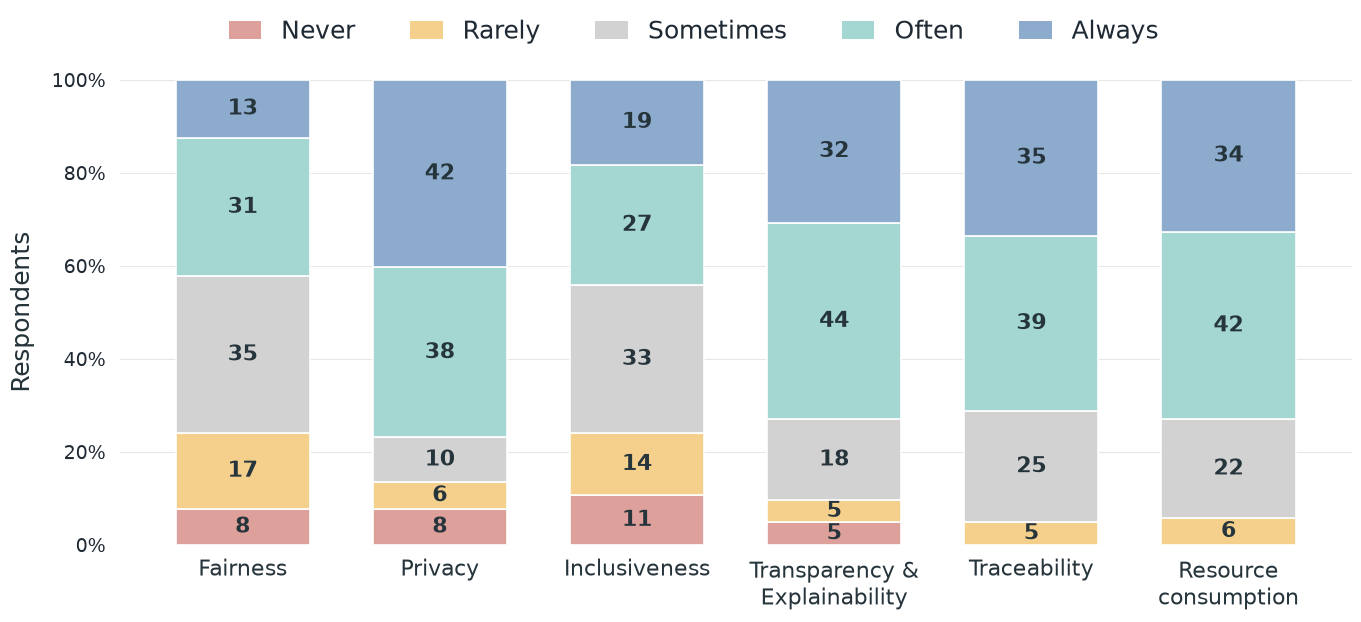

In [12]:
# Build the ordered response table directly from the workbook.
levels = ['Never', 'Rarely', 'Sometimes', 'Often', 'Always']
aspects = [
    'Fairness', 'Privacy', 'Inclusiveness',
    'Transparency / Explainability', 'Traceability', 'Resource consumption'
]
results = pd.DataFrame([
    col(index).dropna().astype(str).str.strip().value_counts().reindex(levels, fill_value=0)
    for index in range(22, 28)
], index=aspects).astype(int)
valid_n = results.sum(axis=1)
percentages = results.div(valid_n.replace(0, np.nan), axis=0).mul(100).fillna(0)

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib import patheffects

INK = '#26343B'
MUTED = '#647078'
PALE = '#E9E7E1'
PAPER = '#FFFFFF'

colors = [
    "#DEA09A",  # Never
    "#F5D08C",  # Rarely
    "#D2D2D2",  # Sometimes
    "#A4D7D2",  # Often
    "#8DABCC",  # Always
]

labels = [
    'Fairness',
    'Privacy',
    'Inclusiveness',
    'Transparency &\nExplainability',
    'Traceability',
    'Resource\nconsumption'
]

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 14,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'savefig.facecolor': PAPER,
})

fig, ax = plt.subplots(figsize=(14, 7.5))
fig.patch.set_facecolor(PAPER)
ax.set_facecolor(PAPER)

x = np.arange(len(aspects))
bottom = np.zeros(len(aspects), dtype=float)
bar_width = 0.68

for j, (level, color) in enumerate(zip(levels, colors)):
    pct = percentages[level].to_numpy(dtype=float)
    counts = results[level].to_numpy(dtype=int)

    ax.bar(
        x, pct,
        bottom=bottom,
        width=bar_width,
        color=color,
        edgecolor=PAPER,
        linewidth=1.2,
        zorder=3
    )

    for i, (v, count) in enumerate(zip(pct, counts)):
        if count == 0:
            continue

        center = bottom[i] + v / 2

        if v > 4:
            ax.text(
                x[i], center, str(count),
                ha='center',
                va='center',
                fontsize=16,
                fontweight='bold',
                color=INK,
                zorder=5
            )
        else:
            # Small segments: label just outside the bar
            # with a thin connector.
            offset = 0.43 if j % 2 == 0 else -0.43

            annotation = ax.annotate(
                str(count),
                xy=(x[i], center),
                xytext=(x[i] + offset, center),
                ha='center',
                va='center',
                fontsize=16,
                fontweight='semibold',
                color=INK,
                arrowprops=dict(
                    arrowstyle='-',
                    color=MUTED,
                    lw=0.65
                ),
                zorder=6,
                annotation_clip=False
            )
            annotation.set_path_effects([
                patheffects.withStroke(
                    linewidth=3,
                    foreground=PAPER
                )
            ])

    bottom += pct

# X-axis: ethical aspects
ax.set_xticks(x)
ax.set_xticklabels(
    labels,
    fontsize=16,
    color=INK,
    ha='center'
)

# Bar heights show percentages; segment labels show respondent counts.
ax.set_ylim(0, 100)
ax.set_yticks(np.arange(0, 101, 20))
ax.yaxis.set_major_formatter(PercentFormatter(100))

ax.grid(
    axis='y',
    color=PALE,
    linewidth=0.8,
    zorder=0
)
ax.set_axisbelow(True)

ax.tick_params(axis='both', length=0, pad=10)

for spine in ax.spines.values():
    spine.set_visible(False)



# Legend
handles = [
    Patch(facecolor=c, edgecolor='none', label=l)
    for l, c in zip(levels, colors)
]

fig.legend(
    handles=handles,
    ncol=5,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.95),
    frameon=False,
    fontsize=18,
    handlelength=1.3,
    columnspacing=2.2
)

fig.subplots_adjust(
    left=0.09,
    right=0.97,
    top=0.84,
    bottom=0.22
)



ax.set_ylabel(
    'Respondents',
    fontsize=18,
    color=INK,
    labelpad=12
)

ax.yaxis.set_major_formatter(PercentFormatter(100))

ax.tick_params(axis='y', left=False, labelleft=True, labelsize=14)

# Export
fig.savefig(
    'ethical_aspects_stacked_vertical.pdf',
    format='pdf',
    bbox_inches='tight',
    pad_inches=0.20,
    facecolor=PAPER
)

fig.savefig(
    'ethical_aspects_stacked_vertical.png',
    format='png',
    dpi=400,
    bbox_inches='tight',
    pad_inches=0.20,
    facecolor=PAPER
)

plt.show()


## Context dependence

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


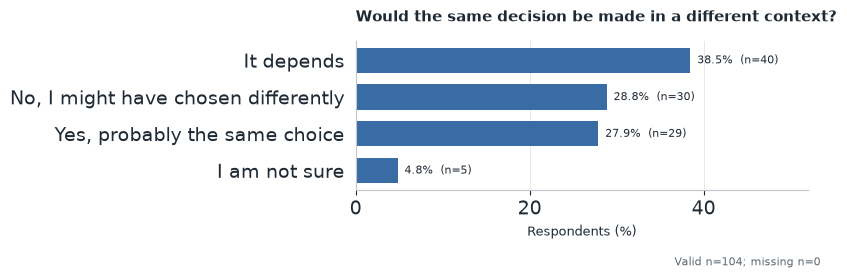

Would you have made the same implementation choice for a different application, domain, or target users?
It depends                             40
No, I might have chosen differently    30
Yes, probably the same choice          29
I am not sure                           5
Name: count, dtype: int64

In [9]:
single(29, 'Would the same decision be made in a different context?', 'context_dependence')

## Open responses

In [10]:
# Question 28 (decision example) and 30 (contextual factors) are open-text responses.
# Avoid misleading frequencies of exact strings.
for i, label in [(28, 'Examples of discretionary decisions'),(30, 'Context-dependent factors')]:
    print(f'{label}: {col(i).notna().sum()}/{N} responses. Qualitative coding needed.')

Examples of discretionary decisions: 100/104 responses. Qualitative coding needed.
Context-dependent factors: 102/104 responses. Qualitative coding needed.


**Reproducibility note.** Outputs are descriptive (no inferential statistics). Text responses are intentionally not treated as quantitative categories; the plots only aggregate closed-ended questions. Denominators and missing-response counts are shown in each figure.